<p align="center">Министерство науки и высшего образования Российской Федерации</p>
<p align="center"><b>Новосибирский государственный технический университет</b></p>
<p align="center">Кафедра автоматизированных систем управления</p>
<br><br><br>
<h1 align="center">Лабораторная работа № 4</h1>
<h3 align="center">«MLOps: учёт экспериментов, реестр моделей и контейнеризация сервиса предсказаний»</h3>
<p align="center"><b>Дисциплина:</b> «Системы искусственного интеллекта и машинное обучение»</p>
<p align="center"><b>Вариант 2.</b> Сервис фильтрации SMS-спама</p>
<br><br><br>


<p align="right"><b>Выполнил:</b> студент гр. АВТ-313<br>Герасимов Сергей Павлович</p>
<p align="right"><b>Проверил:</b> ассистент каф. АСУ<br>Антонянц Егор Николаевич</p>
<p align="right"><b>Дата:</b> 10.11.2026</p>

<br><br>
<p align="center">Новосибирск, 2026</p>

## 1. Цель работы и постановка задачи

**Цель работы:** освоить основы MLOps: учёт и сравнение экспериментов в MLflow, регистрацию и версионирование моделей
в MLflow Model Registry, развёртывание сервиса предсказаний в Docker и Docker Compose, проверку его работы, обновление и откат модели.

**Индивидуальный вариант 2: «Сервис фильтрации SMS-спама».**

| Пункт | Содержание |
|---|---|
| Данные | UCI SMS Spam Collection, https://archive.ics.uci.edu/dataset/228/sms+spam+collection |
| Задача | SMS → `spam` / `ham` (бинарная классификация текста) |
| Алгоритмы | TF-IDF + MultinomialNB и TF-IDF + LogisticRegression |
| Критерий выбора | F1 для класса `spam` на validation (`val_f1_spam`) |
| Особенности | изменять `alpha` (NB) и `C` (LR); дополнительно сравнить precision и recall для spam; API принимает `texts` |

**Что сделано:**
1. Набор данных скачан с UCI и сохранён без изменений в `data/raw`. SHA-256 файла зафиксирован, разбиение 60/20/20 зафиксировано и сохранено в `split.json`.
2. Выполнено **7 экспериментов** (3 × NB, 4 × LR) с разными `alpha`, `C`, `ngram_range` и `class_weight`. Параметры, метрики, теги и артефакты записаны в MLflow.
3. Модели сравнены по `val_f1_spam`. Правило на случай равенства задано до просмотра test.
4. В Model Registry зарегистрированы **2 версии** модели `sms-spam-classifier`, выбранной версии назначен alias `champion`.
5. Модель экспортирована вместе с TF-IDF в одном Pipeline. Написан REST API на FastAPI и собраны образы `sms-spam-api:v1` и `v2`.
6. Проверены корректные и некорректные запросы, а также совпадение ответов API с экспортированной моделью.
7. Показаны обновление v1 → v2 и откат v2 → v1 без повторного обучения.
8. Сервис запущен через Docker Compose с healthcheck, получен статус `healthy`.

## 2. Кратко о MLflow и Docker

* **MLflow Tracking** хранит *experiment* (группу запусков) и *run* (один запуск обучения). У запуска есть *parameters* (настройки до обучения), *metrics* (измеренные значения), *tags* (поясняющие метаданные) и *artifacts* (файлы: модель, матрица ошибок, исходный код, `split.json`).
* **Model Registry** хранит именованную модель и её пронумерованные версии. **Alias** `champion` — изменяемая ссылка на версию. URI `models:/sms-spam-classifier/1` указывает на конкретную версию, а `models:/sms-spam-classifier@champion` — на ту, куда сейчас смотрит alias.
* **Docker image** — пакет приложения с окружением, **container** — запущенный экземпляр образа. Тег (`sms-spam-api:v1`) можно перезаписать, а ID/digest однозначно определяет содержимое образа.
* **Docker Compose** декларативно описывает запуск сервиса: порт, политику перезапуска и healthcheck.

Четыре идентификатора, которые нельзя путать: `run_id` (запуск обучения), номер версии в Registry, тег образа и ID/digest образа.

## 3. Описание набора данных

**Источник:** UCI Machine Learning Repository, *SMS Spam Collection* (Almeida T. A., Gómez Hidalgo J. M., 2011), лицензия CC BY 4.0.
Файл `SMSSpamCollection` из архива сохранён в `data/raw/` **без изменений**. Все преобразования описаны в коде (`src/data.py`).

| Характеристика | Значение |
|---|---|
| Формат | TSV без заголовка, разделитель `\t`, кодировка UTF-8, кавычки не используются (`quoting=QUOTE_NONE`) |
| Объектов | 5574 SMS: 4827 `ham` и 747 `spam` (13,4 % спама) |
| Признак | `text` — исходный текст сообщения на английском |
| Целевая переменная | `label` → `target`: `spam = 1`, `ham = 0` |
| SHA-256 исходного файла | `7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d` |

**Подготовка данных.** В наборе 403 точных дубликата текста, в основном это одинаковые рассылки. Если одинаковое сообщение
попадёт и в train, и в test, оценка будет завышена (утечка). Поэтому дубликаты удаляются **до разбиения**
(`drop_duplicates(subset='text', keep='first')`). Остаётся 5171 объект. Других признаков, кроме текста, нет:
идентификаторов и меток внутри текста не обнаружено.

**Разбиение.** В два шага, со стратификацией по классу и `random_state=42`. Сначала 20 % объектов уходит в финальный test,
затем 25 % оставшихся — в validation. Получается **60/20/20 = 3102 / 1034 / 1035** объектов, доля спама 12,6 % в каждой части.
Индексы всех трёх частей сохраняются в артефакт `split.json` каждого запуска.

**Отсутствие утечки.** `TfidfVectorizer` находится внутри `Pipeline` и обучается только на train. На validation и test применяется
только `transform` уже обученного векторизатора. Test используется ровно один раз, после выбора модели (`src/evaluate.py`).

**Метрики.** Для класса spam: $F1 = 2TP/(2TP+FP+FN)$, $precision = TP/(TP+FP)$, $recall = TP/(TP+FN)$.
Дополнительно считаются accuracy и macro F1. При дисбалансе классов accuracy малоинформативна: модель, которая всегда отвечает
«ham», получит ≈ 0,87. Поэтому основная метрика — F1 для spam.

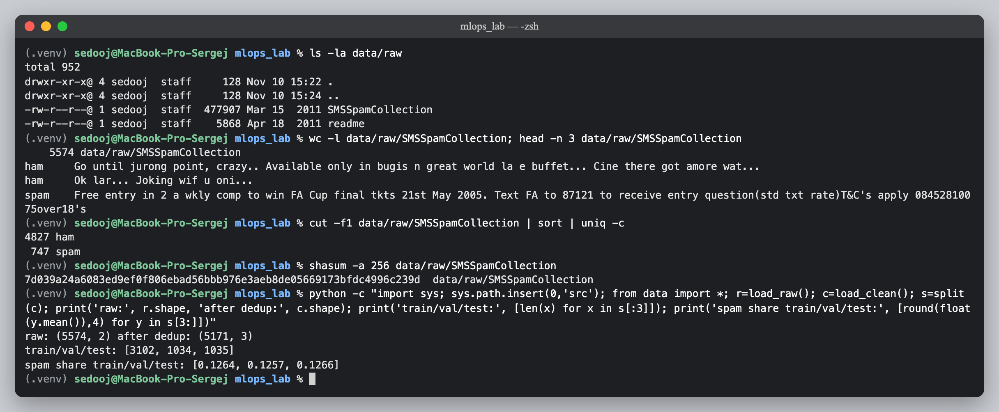

<center><b>Рисунок 1.</b> Исходный файл, распределение классов, SHA-256 и результат разбиения</center>

*Что подтверждает:* данные взяты из первоисточника и не менялись; дедупликация и стратифицированное разбиение 60/20/20 воспроизводятся кодом.

## 4. Программное окружение и структура проекта

| Компонент | Версия |
|---|---|
| ОС | macOS 26.2 (arm64, Apple Silicon) |
| Python | 3.12.10, виртуальное окружение `.venv` |
| MLflow | 3.5.0 (SQLite backend + локальные артефакты, `--serve-artifacts`) |
| scikit-learn / pandas / numpy | 1.7.2 / 2.3.3 / 2.2.6 |
| FastAPI / uvicorn | 0.119.0 / 0.37.0 |
| Docker Engine / Compose | 27.4.0 (Docker Desktop) / v2.31.0 |
| Базовый образ | `python:3.12-slim` (digest `sha256:aa943ce411423c7582288f18707ff66eddcbaeb510502d747a72aeb34f30d159`) |

Методичка написана для Ubuntu. Работа выполнялась на macOS с Docker Desktop, поэтому `sudo` перед `docker` не нужен,
остальные команды не отличаются.
`requirements.txt` фиксирует прямые зависимости, `requirements.lock.txt` (`pip freeze`, 131 пакет) — полный снимок окружения.

```
mlops_lab/
  requirements.txt, requirements.lock.txt
  Dockerfile, compose.yaml, .dockerignore
  README.md
  data/raw/SMSSpamCollection, readme
  src/data.py
  src/train.py
  src/promote.py
  src/export_model.py
  src/evaluate.py
  src/app.py
  src/check_api.py
  mlflow-data/
  exported_model/
  sample_request.json, expected_predictions.json, test_metrics.json
  screenshots/
```

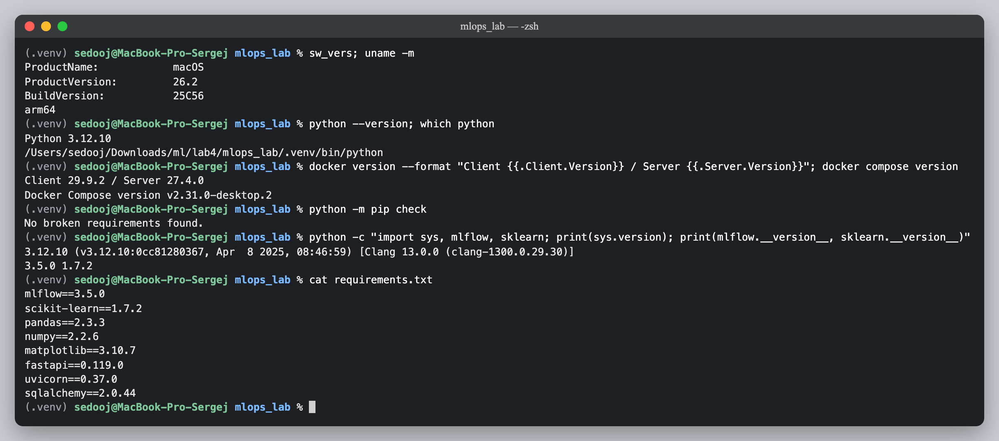

<center><b>Рисунок 2.</b> Проверка окружения: ОС, Python из .venv, Docker, версии MLflow и scikit-learn</center>

*Что подтверждает:* используется интерпретатор виртуального окружения, зависимости совместимы (`pip check`), версии совпадают с зафиксированными.

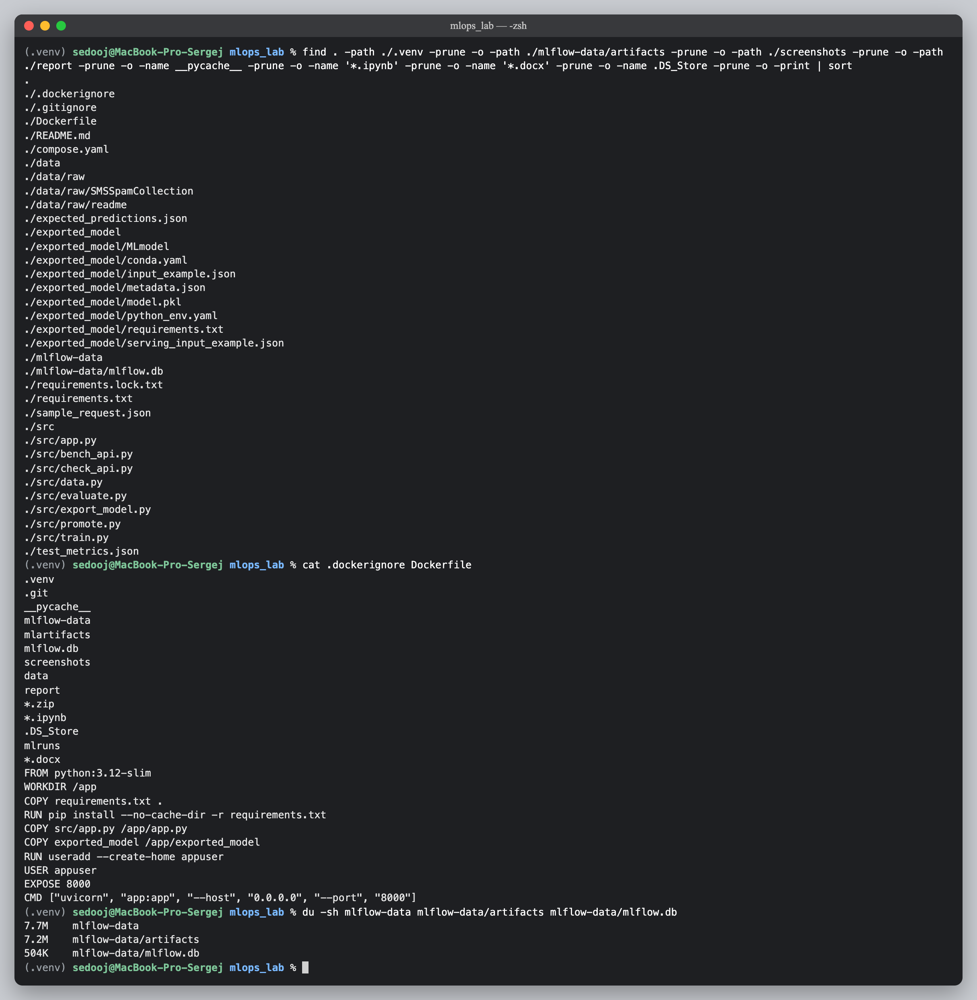

<center><b>Рисунок 3.</b> Структура проекта, .dockerignore и Dockerfile</center>

*Что подтверждает:* проект содержит все требуемые файлы; локальное окружение, база MLflow и данные не попадают в контекст сборки образа.

## 5. Последовательность выполнения работы

### 5.1 Запуск сервера MLflow (терминал A)

```bash
source .venv/bin/activate
mkdir -p mlflow-data/artifacts screenshots
mlflow server --backend-store-uri sqlite:///mlflow-data/mlflow.db \
  --artifacts-destination ./mlflow-data/artifacts --serve-artifacts \
  --host 127.0.0.1 --port 5000
```
В терминале B: `export MLFLOW_TRACKING_URI=http://127.0.0.1:5000`, затем `curl -f http://127.0.0.1:5000/health`, ответ `OK`.
Сервер слушает только `127.0.0.1`, снаружи он недоступен.

### 5.2 Что делает `train.py`
Скрипт загружает очищенные данные и строит фиксированное разбиение. Модель собирается так:
`Pipeline(ColumnTransformer(TfidfVectorizer(ngram_range, sublinear_tf=True) по столбцу text) → MultinomialNB(alpha) | LogisticRegression(C, class_weight))`.
Затем скрипт создаёт run в эксперименте `lab4-sms-spam` и записывает:
* **params:** `algorithm`, `alpha` или `C`, `class_weight`, `ngram_range`, `seed`, размеры выборок;
* **metrics:** `val_f1_spam`, `val_precision_spam`, `val_recall_spam`, `val_accuracy`, `val_f1_macro`;
* **tags:** `dataset_sha256`, `variant=2`, `selection_metric=val_f1_spam`;
* **artifacts:** матрицу ошибок на validation, `split.json`, исходники (`train.py`, `data.py`), `requirements.txt` и модель с `signature` и `input_example`;
* **dataset input:** описание очищенного набора (`log_input`).

Векторизатор и классификатор логируются **одним Pipeline**: при загрузке модели не нужно повторять предобработку вручную.
Входом модели служит таблица с одним столбцом `text`, поэтому signature выглядит так: `[text: string] → long`.

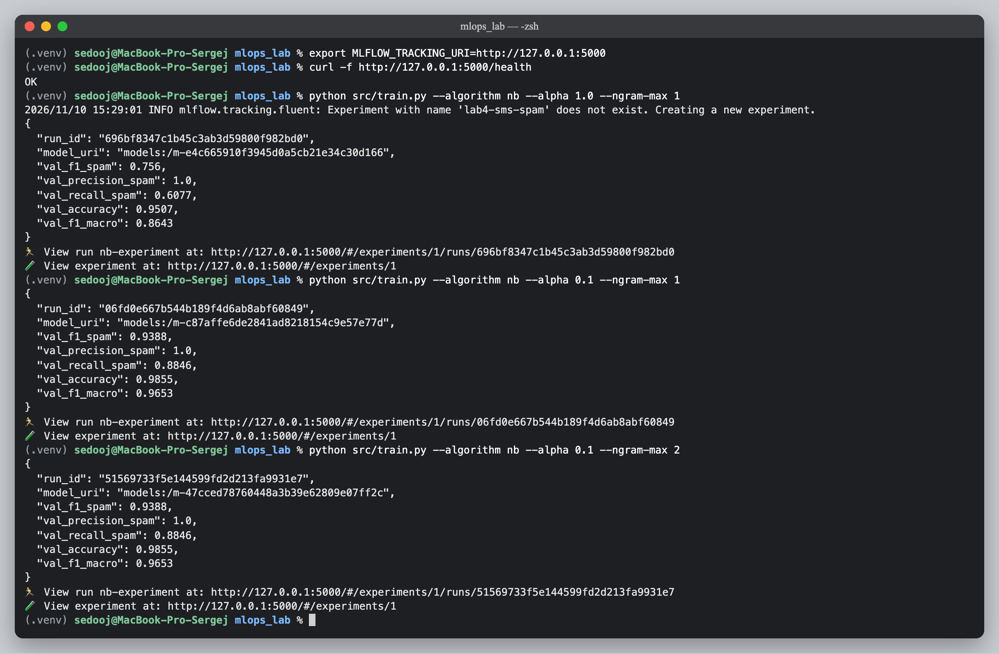

<center><b>Рисунок 4.</b> Запуски MultinomialNB (alpha = 1.0 и 0.1, ngram (1,1) и (1,2))</center>

*Что подтверждает:* каждый запуск завершился, напечатаны `run_id`, `model_uri` и validation-метрики.

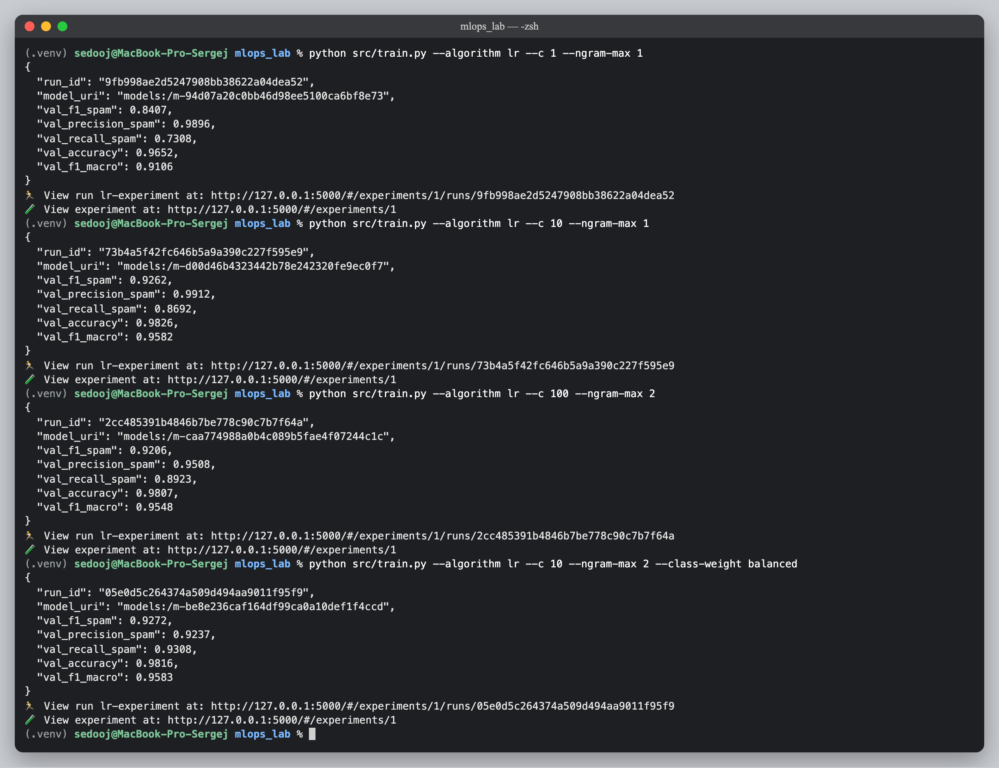

<center><b>Рисунок 5.</b> Запуски LogisticRegression (C = 1, 10, 100; class_weight = balanced)</center>

*Что подтверждает:* выполнено ещё четыре успешных эксперимента, всего 7 (требуется не менее 6).

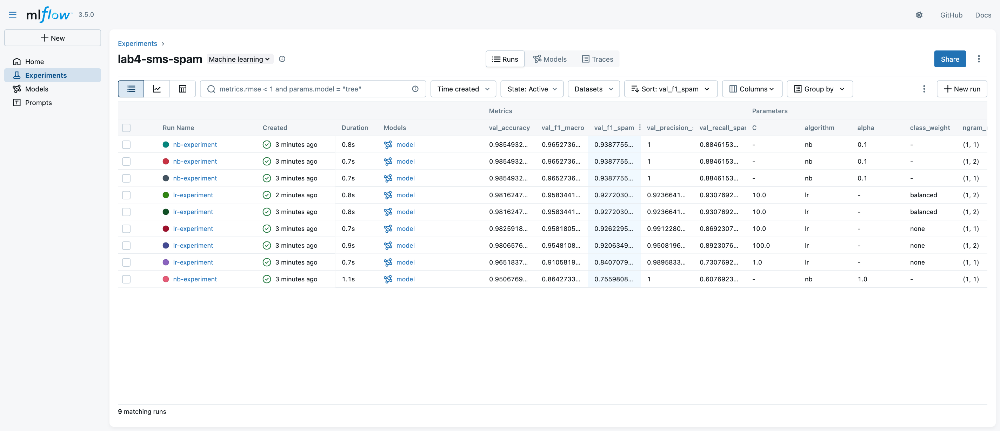

<center><b>Рисунок 6.</b> MLflow UI: эксперимент lab4-sms-spam, запуски отсортированы по val_f1_spam</center>

*Что подтверждает:* в одной таблице видны параметры (algorithm, alpha, C, ngram_range, class_weight) и validation-метрики всех запусков; все запуски в статусе FINISHED.

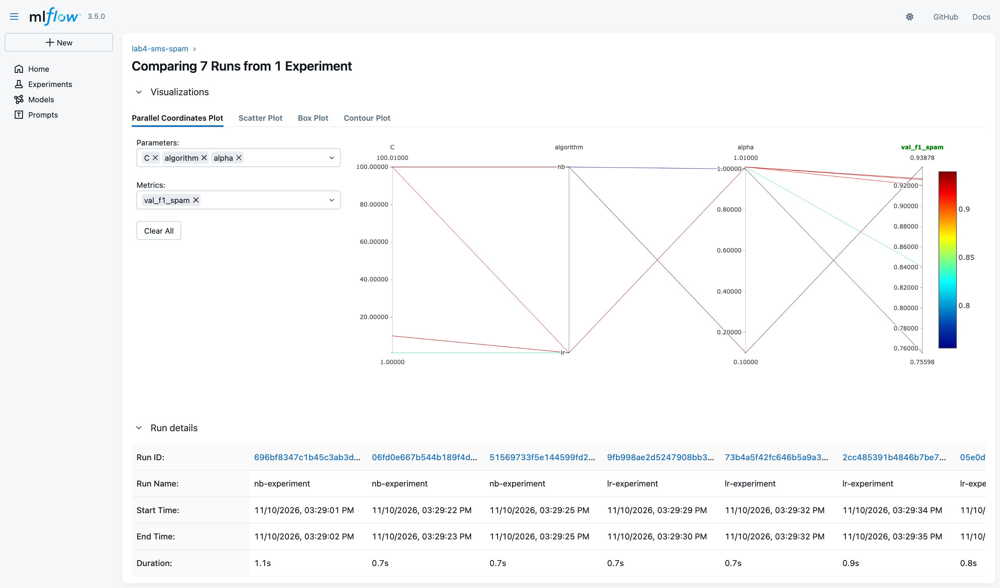

<center><b>Рисунок 7.</b> MLflow UI: сравнение 7 экспериментальных запусков (parallel coordinates по val_f1_spam)</center>

*Что подтверждает:* встроенное сравнение MLflow показывает связь гиперпараметров с целевой метрикой.

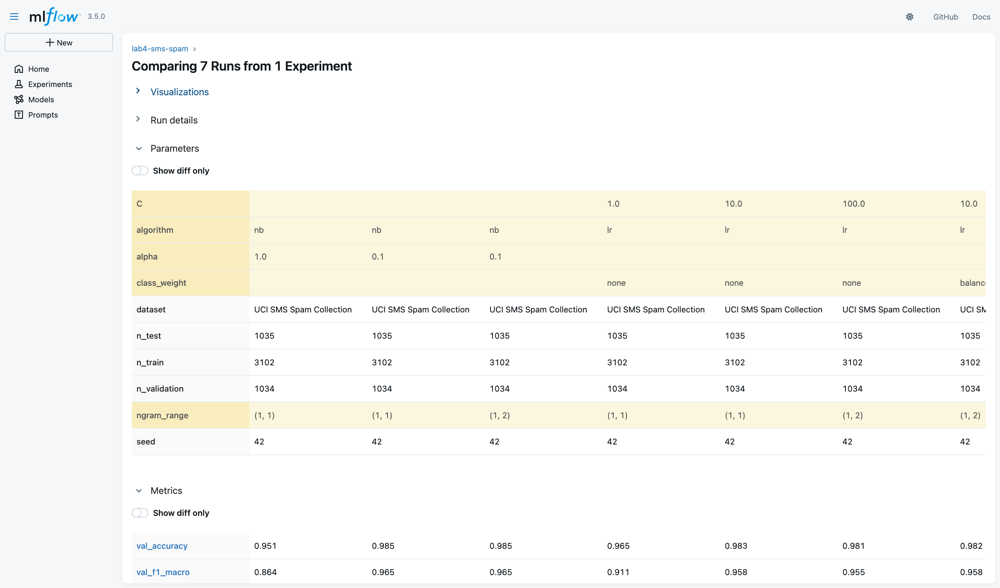

<center><b>Рисунок 8.</b> MLflow UI: сравнение запусков, таблицы параметров и метрик</center>

*Что подтверждает:* параметры и метрики нескольких запусков видны одновременно; одинаковые размеры выборок и seed подтверждают одинаковое разбиение.

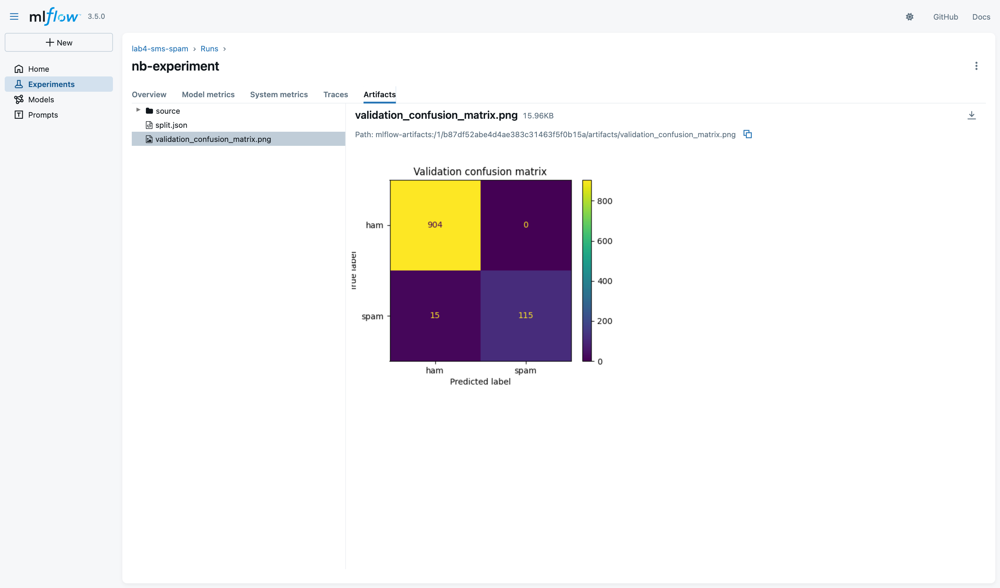

<center><b>Рисунок 9.</b> Артефакты выбранного запуска: исходники, split.json, матрица ошибок на validation</center>

*Что подтверждает:* запуск хранит всё нужное для воспроизведения и анализа; на validation у модели нет ложных срабатываний (0 FP).

## 6. Сравнительная таблица экспериментов

Таблица ниже собрана из MLflow (`mlflow.search_runs`, файл `report/experiments.csv`). Запуски 1–7 — эксперименты,
8–9 — повторные запуски с `--register` для регистрации версий. Их метрики совпадают с запусками 2 и 7, что подтверждает воспроизводимость.

In [1]:
import json
import pandas as pd

df = pd.read_csv('report/experiments.csv')
df = df.rename(columns={'tags.mlflow.runName': 'run_name', 'params.algorithm': 'algorithm', 'params.alpha': 'alpha',
                        'params.C': 'C', 'params.ngram_range': 'ngram_range', 'params.class_weight': 'class_weight',
                        'metrics.val_f1_spam': 'val_f1_spam', 'metrics.val_precision_spam': 'val_prec_spam',
                        'metrics.val_recall_spam': 'val_rec_spam', 'metrics.val_accuracy': 'val_acc',
                        'metrics.val_f1_macro': 'val_f1_macro'})
df['purpose'] = ['эксперимент'] * 7 + ['регистрация -> v1', 'регистрация -> v2']
pd.set_option('display.width', 250)
df[['n', 'run_id', 'algorithm', 'alpha', 'C', 'ngram_range', 'class_weight', 'val_f1_spam', 'val_prec_spam',
    'val_rec_spam', 'val_acc', 'val_f1_macro', 'status', 'purpose']].round(4).astype(object).fillna('—')

,n,run_id,algorithm,alpha,C,ngram_range,class_weight,val_f1_spam,val_prec_spam,val_rec_spam,val_acc,val_f1_macro,status,purpose
0,1,696bf8347c1b45c3ab3d59800f982bd0,nb,1.0,—,"(1, 1)",—,0.756,1.0,0.6077,0.9507,0.8643,FINISHED,эксперимент
1,2,06fd0e667b544b189f4d6ab8abf60849,nb,0.1,—,"(1, 1)",—,0.9388,1.0,0.8846,0.9855,0.9653,FINISHED,эксперимент
2,3,51569733f5e144599fd2d213fa9931e7,nb,0.1,—,"(1, 2)",—,0.9388,1.0,0.8846,0.9855,0.9653,FINISHED,эксперимент
3,4,9fb998ae2d5247908bb38622a04dea52,lr,—,1.0,"(1, 1)",none,0.8407,0.9896,0.7308,0.9652,0.9106,FINISHED,эксперимент
4,5,73b4a5f42fc646b5a9a390c227f595e9,lr,—,10.0,"(1, 1)",none,0.9262,0.9912,0.8692,0.9826,0.9582,FINISHED,эксперимент
5,6,2cc485391b4846b7be778c90c7b7f64a,lr,—,100.0,"(1, 2)",none,0.9206,0.9508,0.8923,0.9807,0.9548,FINISHED,эксперимент
6,7,05e0d5c264374a509d494aa9011f95f9,lr,—,10.0,"(1, 2)",balanced,0.9272,0.9237,0.9308,0.9816,0.9583,FINISHED,эксперимент
7,8,b87df52abe4d4ae383c31463f5f0b15a,nb,0.1,—,"(1, 1)",—,0.9388,1.0,0.8846,0.9855,0.9653,FINISHED,регистрация -> v1
8,9,1ca9d22a76144f1fa10bad1c3dfbe708,lr,—,10.0,"(1, 2)",balanced,0.9272,0.9237,0.9308,0.9816,0.9583,FINISHED,регистрация -> v2


**Наблюдения по validation (1034 SMS, из них 130 spam):**
* **MultinomialNB.** Уменьшение сглаживания `alpha` с 1.0 до 0.1 резко повышает recall спама (0,608 → 0,885) при precision = 1,0. Сильное сглаживание «размывает» редкие спам-слова. Биграммы (1,2) при `alpha=0.1` дают **те же самые** предсказания на validation.
* **LogisticRegression.** Рост `C` (ослабление регуляризации) с 1 до 10 повышает F1 с 0,841 до 0,926. При `C=100` precision падает (0,951), модель начинает переобучаться. `class_weight='balanced'` сдвигает баланс в сторону recall (0,931, лучший среди всех), но precision снижается до 0,924.
* Precision и recall для spam сравнены отдельно, как требует вариант: NB даёт нулевое число ложных срабатываний, но пропускает около 11,5 % спама. LR с `balanced` пропускает меньше спама, зато 10 нормальных SMS из 904 помечает как спам.

## 7. Обоснование выбора модели и итоговая оценка

**Правило выбора, заданное до просмотра test:**
1. максимальный `val_f1_spam`;
2. при равенстве — более простая модель (меньше признаков: `ngram_range=(1,1)` проще, чем `(1,2)`; NB проще, чем LR).

Максимум `val_f1_spam = 0.9388` у двух запусков: NB `alpha=0.1` с `(1,1)` и с `(1,2)`. По второму пункту правила выбрана
**TF-IDF(1,1) + MultinomialNB(alpha=0.1)**. Дополнительный довод для спам-фильтра: precision = 1,0, то есть ни одно нормальное
сообщение на validation не попало в спам. Ложная блокировка обычной SMS обходится пользователю дороже пропущенного спама.

Модель зарегистрирована как **версия 1** (run `b87df52abe4d4ae383c31463f5f0b15a`) и получила alias `champion`.
Вторая версия — **LR(C=10, ngram (1,2), class_weight=balanced)**, лучшая по recall. Она нужна для демонстрации обновления
и отката и как альтернатива, если важнее пропускать меньше спама.

**Итоговая оценка на test** (`src/evaluate.py`, 1035 объектов, выполнена один раз после выбора):

In [2]:
tm = json.load(open('test_metrics.json'))
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in tm.items() if k != 'confusion_matrix'}, indent=2))
pd.DataFrame(tm['confusion_matrix'], index=['true ham', 'true spam'], columns=['pred ham', 'pred spam'])

{
  "model_version": "1",
  "n_test": 1035,
  "test_f1_spam": 0.92,
  "test_precision_spam": 0.9664,
  "test_recall_spam": 0.8779,
  "test_accuracy": 0.9807,
  "test_f1_macro": 0.9545
}


,pred ham,pred spam
true ham,900,4
true spam,16,115


Значения на test (F1_spam = 0.9200, precision = 0.9664, recall = 0.8779,
accuracy = 0.9807) близки к validation (0,9388 / 1,0 / 0,8846 / 0,9855). Сильного переобучения на validation при
выборе гиперпараметров не было. На test появилось 4 ложных срабатывания из 904 ham, поэтому precision = 1,0 на validation
не стоит считать гарантией. Результаты test **не использовались** для дальнейшей настройки.

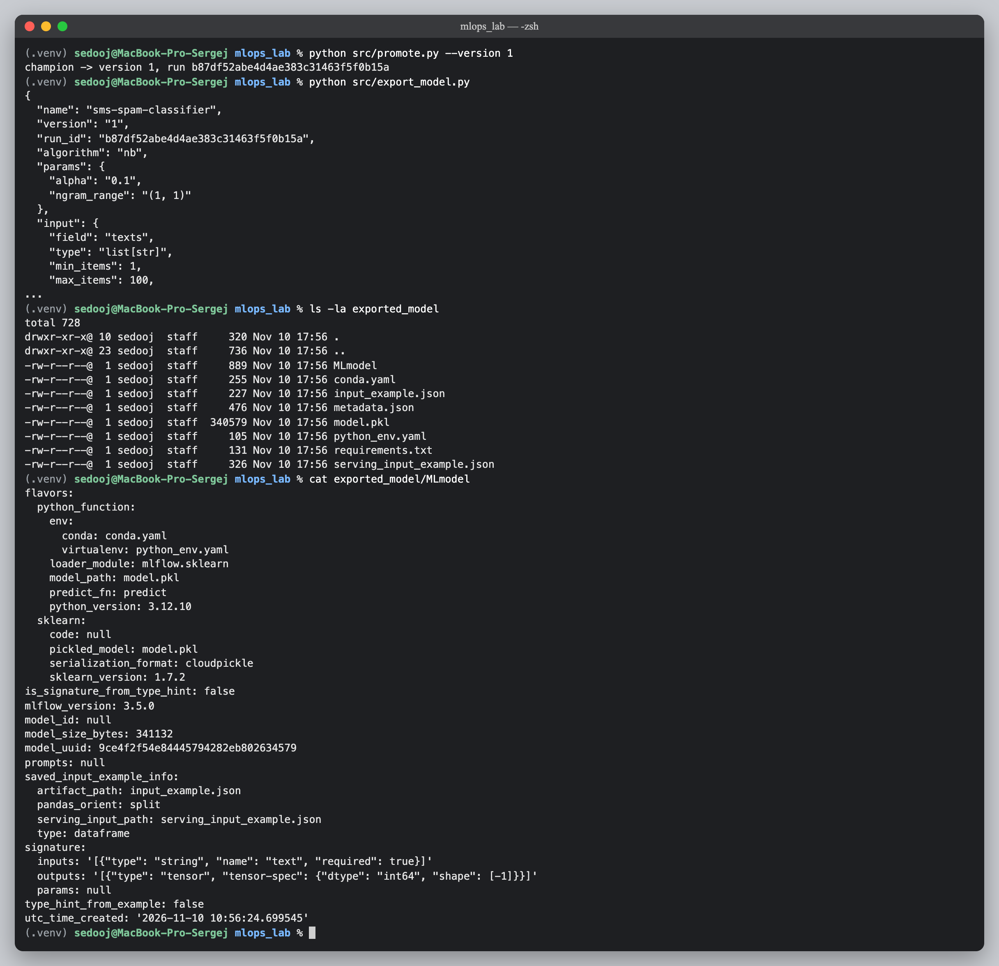

<center><b>Рисунок 10.</b> Назначение champion → версия 1 и экспорт модели</center>

*Что подтверждает:* `export_model.py` один раз резолвит alias в конкретный номер версии и сохраняет MLflow-модель (с сигнатурой и примером входа) и metadata.json в `exported_model/`.

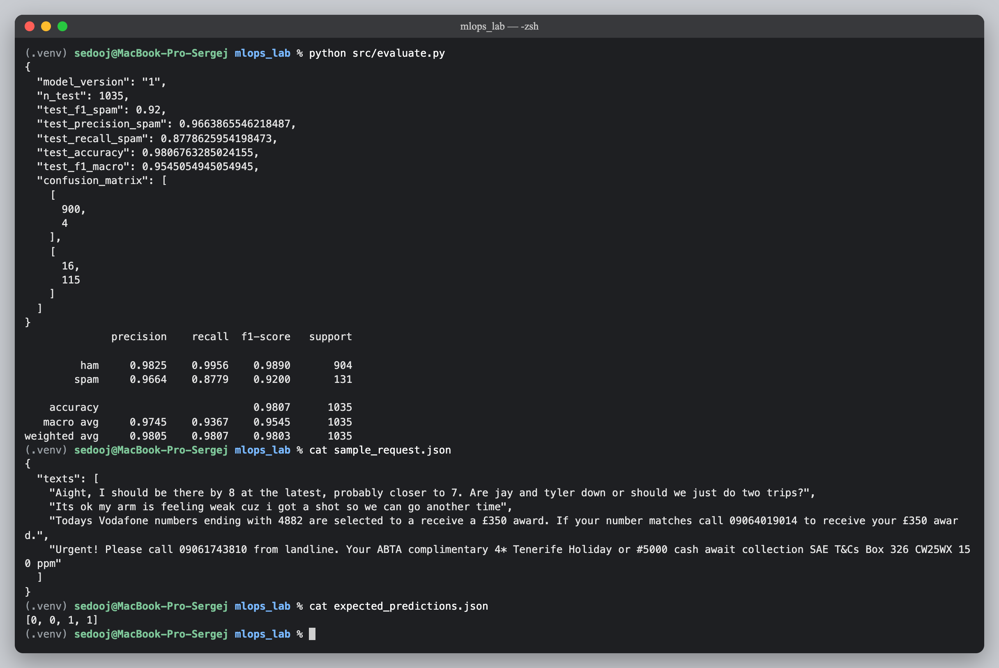

<center><b>Рисунок 11.</b> Итоговая оценка на test и эталонный запрос для проверки доставки</center>

*Что подтверждает:* итоговые метрики получены на отложенной выборке; `sample_request.json` содержит 4 реальных test-SMS (2 ham, 2 spam), `expected_predictions.json` — ответы экспортированной модели.

## 8. Регистрация версий модели и назначение alias champion

```bash
python src/train.py --algorithm nb --alpha 0.1 --ngram-max 1 --register
python src/train.py --algorithm lr --c 10 --ngram-max 2 --class-weight balanced --register
python src/promote.py --version 1
```

| Версия Registry | run_id | Модель | val_f1_spam | Alias |
|---|---|---|---|---|
| 1 | `b87df52abe4d4ae383c31463f5f0b15a` | TF-IDF(1,1) + MultinomialNB(alpha=0.1) | 0.9388 | **champion** |
| 2 | `1ca9d22a76144f1fa10bad1c3dfbe708` | TF-IDF(1,2) + LR(C=10, balanced) | 0.9272 | — |

Alias не создаёт новую модель, а только переставляет указатель. Работающий контейнер от этого не меняется:
чтобы сменить модель в сервисе, нужно заново экспортировать её и собрать новый образ.

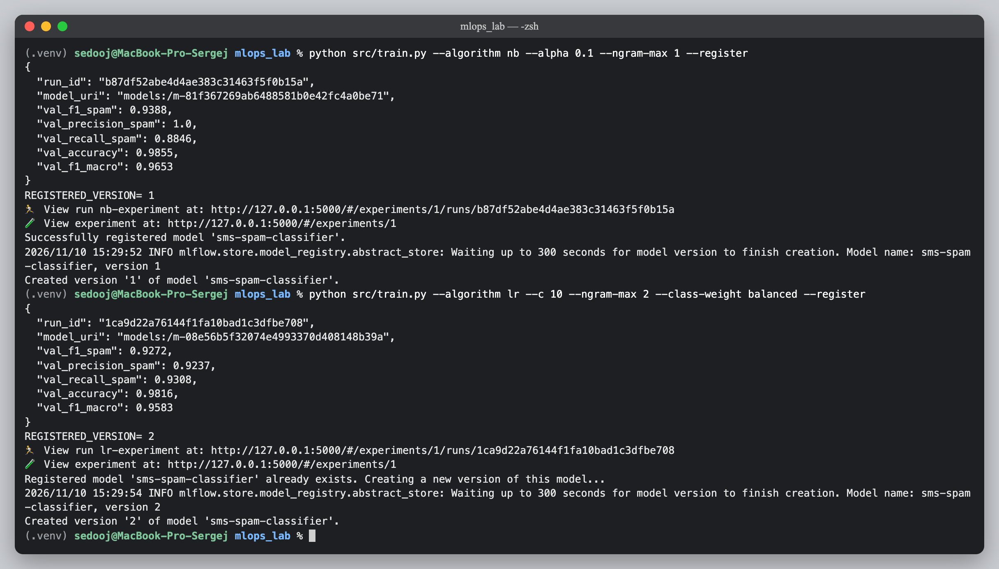

<center><b>Рисунок 12.</b> Регистрация двух версий модели sms-spam-classifier</center>

*Что подтверждает:* созданы версии 1 и 2 одной registry-модели, у каждой есть свой run_id.

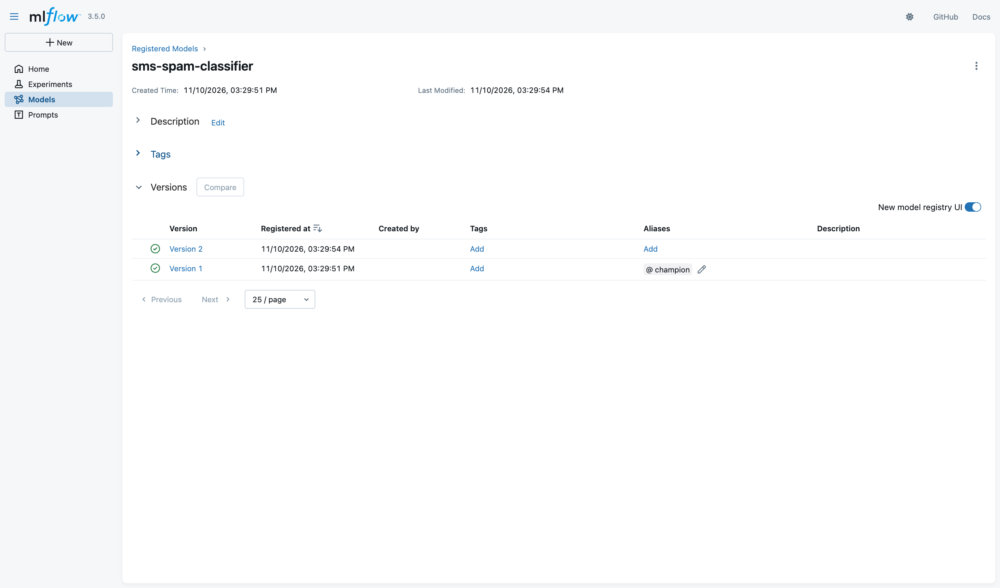

<center><b>Рисунок 13.</b> MLflow Model Registry: две версии sms-spam-classifier, alias @champion у версии 1</center>

*Что подтверждает:* в реестре не меньше двух версий, alias champion назначен выбранной по validation версии.

## 9. Описание API и проверка запросов

Сервис `src/app.py` (FastAPI) загружает `exported_model` **один раз при старте** и к MLflow не обращается.

| Метод | Путь | Ответ |
|---|---|---|
| GET | `/health` | `{"status": "ok", "model_version": "1"}`, нужен для healthcheck |
| GET | `/metadata` | имя, версия Registry, run_id, алгоритм и параметры, классы, контракт входа, SHA-256 данных |
| POST | `/predict` | предсказания для пакета SMS |
| GET | `/docs` | Swagger UI |

**Формат входа** (адаптация методички под текстовый вариант: вместо таблицы из 13 чисел — список строк):
```json
{"texts": ["Hey, are we still meeting for lunch tomorrow?", "WINNER!! You have won a FREE trip..."]}
```
Правила валидации (Pydantic, `extra='forbid'`, `strict=True`): `texts` — список из 1–100 элементов;
каждый элемент — строка, после `strip()` непустая и не длиннее 1000 символов (самая длинная SMS в наборе — 910 символов).
Лишние поля и значения не строкового типа отклоняются.

**Формат ответа:**
```json
{"predictions": [0, 1], "labels": ["ham", "spam"], "spam_probability": [0.0008, 0.9935],
 "model_version": "1", "latency_ms": 2.1}
```
`latency_ms` — время построения DataFrame и предсказания внутри обработчика. Тексты сообщений в лог не пишутся,
логируются только версия, число строк и время.

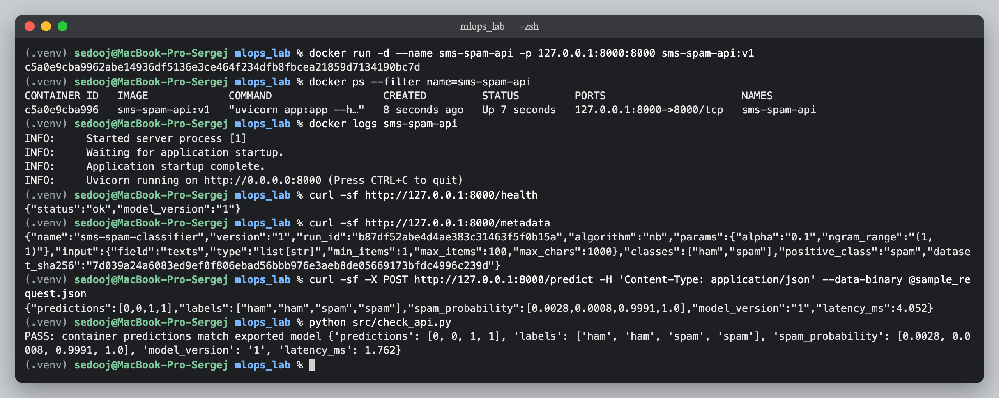

<center><b>Рисунок 14.</b> Запуск контейнера v1, /health, /metadata, /predict и smoke-test</center>

*Что подтверждает:* сервис работает в контейнере; предсказания API `[0, 0, 1, 1]` совпадают с `expected_predictions.json` экспортированной модели (`PASS`).

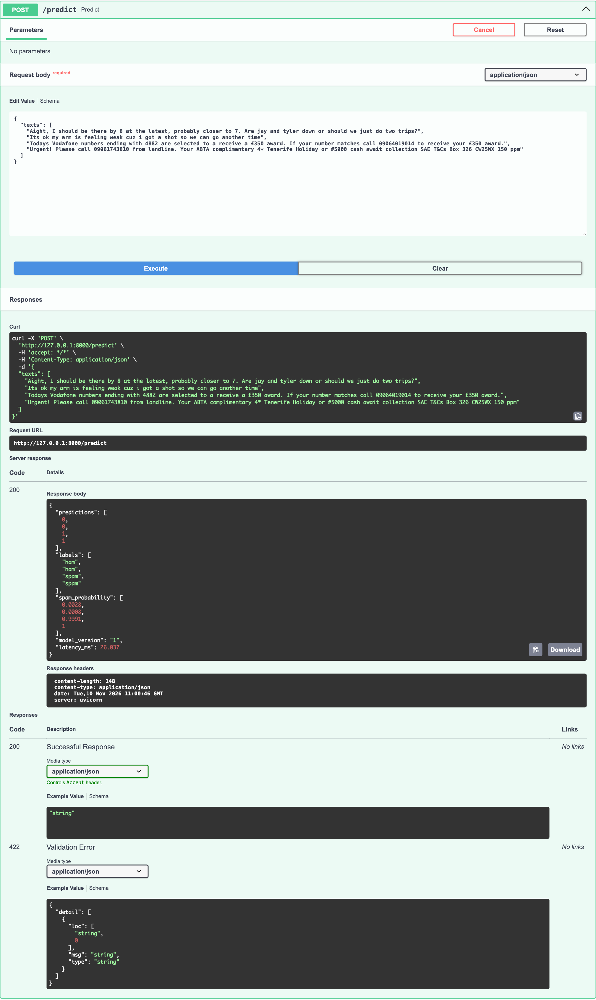

<center><b>Рисунок 15.</b> Swagger UI (/docs): POST /predict с содержимым sample_request.json, код 200</center>

*Что подтверждает:* интерактивная документация работает, запрос через UI возвращает те же предсказания и версию модели 1.

**Проверка некорректных запросов.** Все они должны возвращать **422** с понятным описанием ошибки, а не 500.

| № | Запрос | Что проверяет | Код |
|---|---|---|---|
| 1 | `{"texts": []}` | пустой пакет | 422 `too_short` |
| 2 | `{"text": ["hello"]}` | неверное имя поля (обязательное поле отсутствует) | 422 `missing` + `extra_forbidden` |
| 3 | `{"texts": ["   "]}` | пустая строка из пробелов | 422 `string_too_short` |
| 4 | `{"texts": ["Call now!"], "debug": true}` | лишнее поле | 422 `extra_forbidden` |
| 5 | `{"texts": [123]}` | неверный тип элемента | 422 `string_type` |
| 6 | `{"texts": "WINNER! ..."}` | строка вместо списка | 422 `list_type` |
| 7 | `not a json` | некорректный JSON | 422 `json_invalid` |
| 8 | `{"texts": ["Hey, are we still meeting for lunch tomorrow?"]}` | корректный запрос, один объект | **200**, `ham`, p(spam)=0.0008 |
| 9 | `{"texts": ["WINNER!! You have won a FREE trip. Call 09061701461 ..."]}` | корректный запрос, один объект | **200**, `spam`, p(spam)=0.9935 |

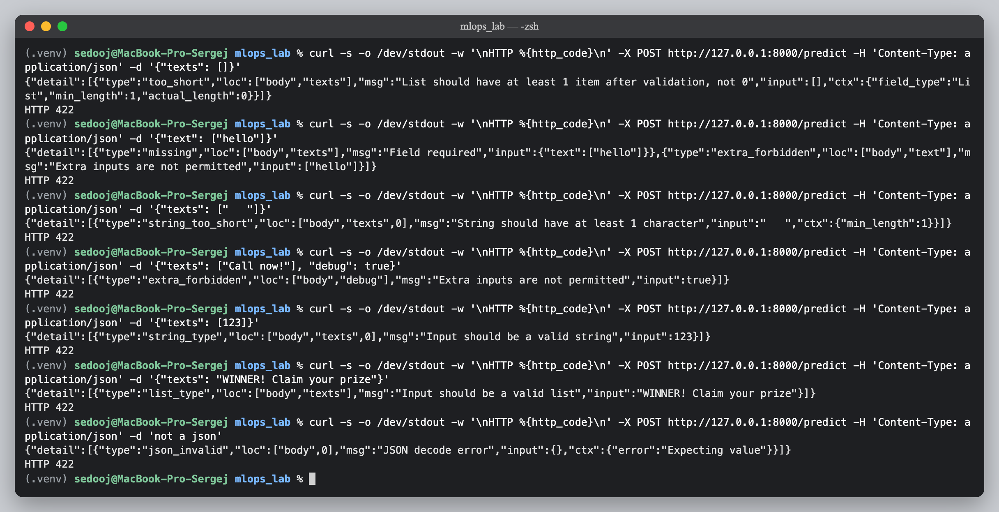

<center><b>Рисунок 16.</b> Ответы 422 на некорректные запросы</center>

*Что подтверждает:* вход проверяется контролируемо: пустой пакет, отсутствующее или лишнее поле, неверный тип, пустая строка и битый JSON дают 422.

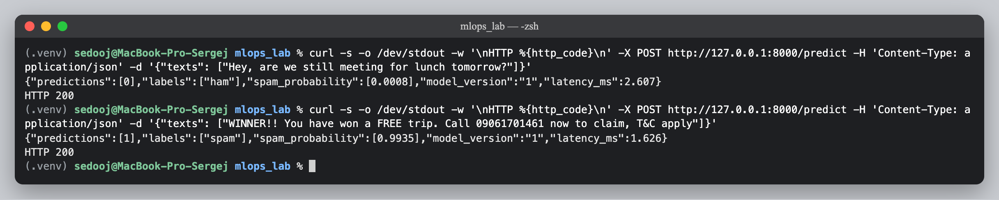

<center><b>Рисунок 17.</b> Корректные запросы с одним объектом (ham и spam)</center>

*Что подтверждает:* для одиночного сообщения API возвращает 200, класс, вероятность спама и версию модели.

## 10. Сборка и запуск Docker-контейнера

```bash
docker build -t sms-spam-api:v1 .
docker image ls sms-spam-api
docker image inspect sms-spam-api:v1 --format '{{.Id}}'
docker run -d --name sms-spam-api -p 127.0.0.1:8000:8000 sms-spam-api:v1
python src/check_api.py
```
* `FROM python:3.12-slim` → `pip install -r requirements.txt` → копирование только `app.py` и `exported_model` → запуск от непривилегированного пользователя `appuser`.
* Внутри контейнера uvicorn слушает `0.0.0.0:8000`, иначе опубликованный порт не работал бы. На хосте порт опубликован только на `127.0.0.1:8000`, поэтому сервис доступен лишь локально.
* Сборка с нуля (`--no-cache`) заняла **≈200 с**: почти всё время ушло на `pip install`. Повторная сборка v2 использовала кэш слоя зависимостей и прошла за несколько секунд.
* Размер образа ≈ **931 МБ**. Основную часть занимают MLflow с зависимостями, scikit-learn и scipy, сама модель весит ≈ 340 КБ.

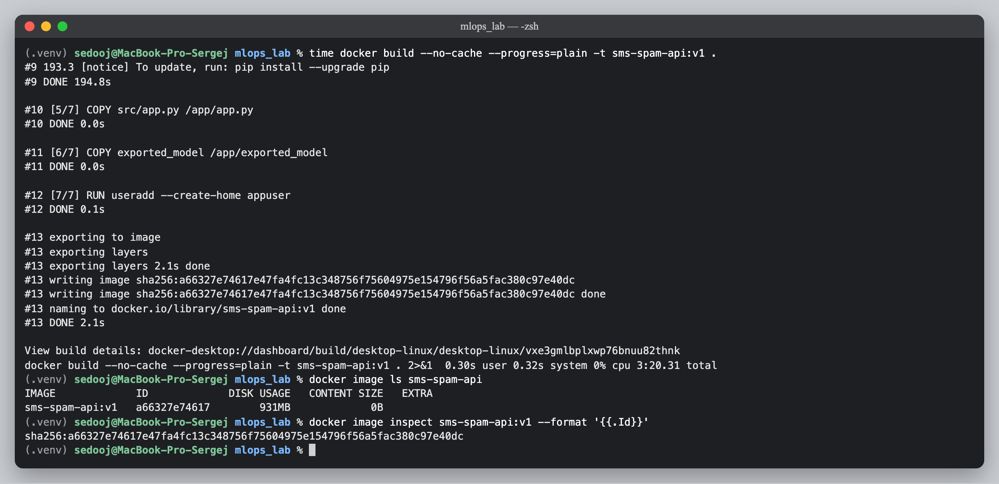

<center><b>Рисунок 18.</b> Успешная сборка sms-spam-api:v1 и ID образа</center>

*Что подтверждает:* образ собран, ID: `sha256:a66327e74617…`.

**Совпадение ответов API и экспортированной модели.** `check_api.py` отправляет `sample_request.json` в контейнер и сравнивает
`predictions` с `expected_predictions.json`, который `export_model.py` получил локально от той же экспортированной модели.
Результат: `PASS` (рисунок выше). Вероятности спама из API (0.0028, 0.0008, 0.9991, 1.0) также соответствуют модели версии 1.

**Длительность ответа и эксплуатационная проверка.** Один и тот же запрос (4 SMS) отправлен 10 раз:

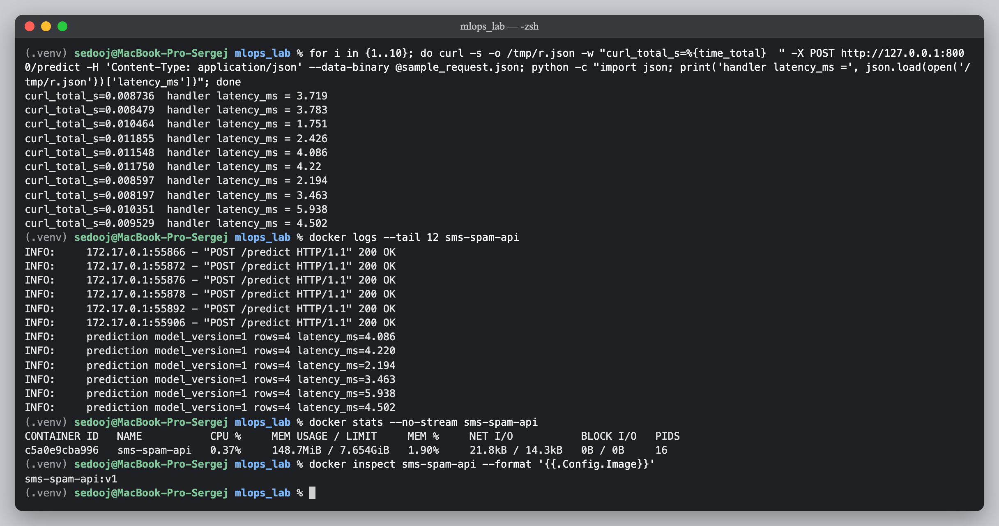

<center><b>Рисунок 19.</b> Десять одинаковых запросов: время обработчика и полное время curl; логи и ресурсы контейнера</center>

*Что подтверждает:* время обработчика ≈ 1,8–5,9 мс, полный round-trip curl ≈ 8,2–11,9 мс. Контейнер занимает ≈ 148 МиБ ОЗУ, в логах есть версия, число строк и latency.

`latency_ms` меньше времени `curl`: в него не входят сетевой стек, проброс порта Docker Desktop, разбор JSON и сериализация ответа.
Проверка `/health` подтверждает только то, что сервис жив. Качество модели и дрейф данных она не измеряет.

## 11. Обновление и откат

Перед обновлением в `/metadata` работающего контейнера `sms-spam-api:v1` указана **версия модели 1**.
Для учебной демонстрации доставки вторая версия временно назначается champion. Это не означает, что она лучше по validation.

```bash
python src/promote.py --version 2
python src/export_model.py
docker build -t sms-spam-api:v2 .
docker stop sms-spam-api && docker rm sms-spam-api
docker run -d --name sms-spam-api -p 127.0.0.1:8000:8000 sms-spam-api:v2
curl -sf http://127.0.0.1:8000/metadata
python src/check_api.py
docker stop sms-spam-api && docker rm sms-spam-api
docker run -d --name sms-spam-api -p 127.0.0.1:8000:8000 sms-spam-api:v1
python src/promote.py --version 1
curl -sf http://127.0.0.1:8000/metadata
python src/export_model.py
python src/check_api.py
```

| Состояние | Тег образа | ID образа | Версия модели (Registry) | run_id | p(spam) для sample_request |
|---|---|---|---|---|---|
| исходное | `sms-spam-api:v1` | `sha256:a66327e74617…` | 1 (NB) | `b87df52a…` | 0.0028, 0.0008, 0.9991, 1.0 |
| после обновления | `sms-spam-api:v2` | `sha256:f6257bffbc0c…` | 2 (LR) | `1ca9d22a…` | 0.0606, 0.003, 0.9672, 0.9904 |
| после отката | `sms-spam-api:v1` | `sha256:a66327e74617…` | 1 (NB) | `b87df52a…` | 0.0028, 0.0008, 0.9991, 1.0 |

На четырёх эталонных SMS обе версии дают одинаковые классы `[0, 0, 1, 1]`. Смену модели при этом видно по `model_version`,
`run_id` и вероятностям. Для отката не понадобились ни обучение, ни пересборка: контейнер просто запущен из сохранённого образа `v1`.

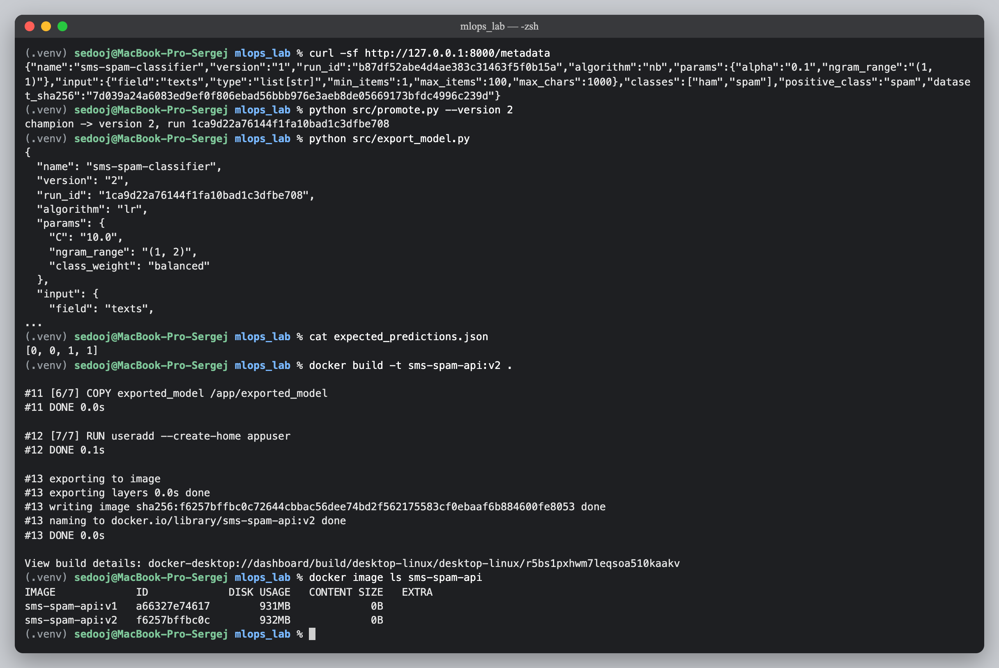

<center><b>Рисунок 20.</b> Обновление: champion → 2, экспорт версии 2, сборка sms-spam-api:v2</center>

*Что подтверждает:* в metadata работающего v1 версия 1; после экспорта metadata указывает версию 2; образ v2 собран с кэшированным слоем зависимостей.

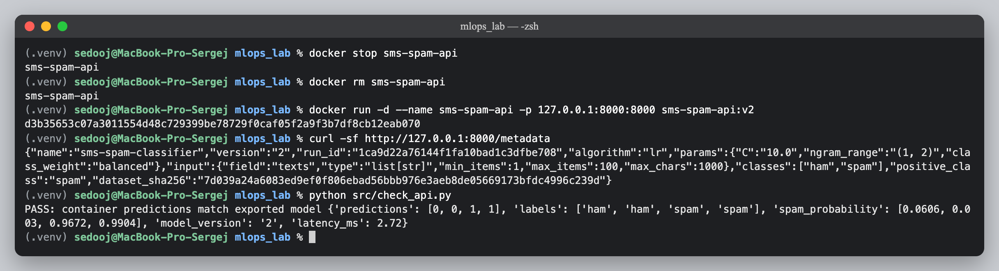

<center><b>Рисунок 21.</b> Запуск контейнера из образа v2</center>

*Что подтверждает:* /metadata возвращает версию 2 (LR, C=10, balanced), smoke-test проходит.

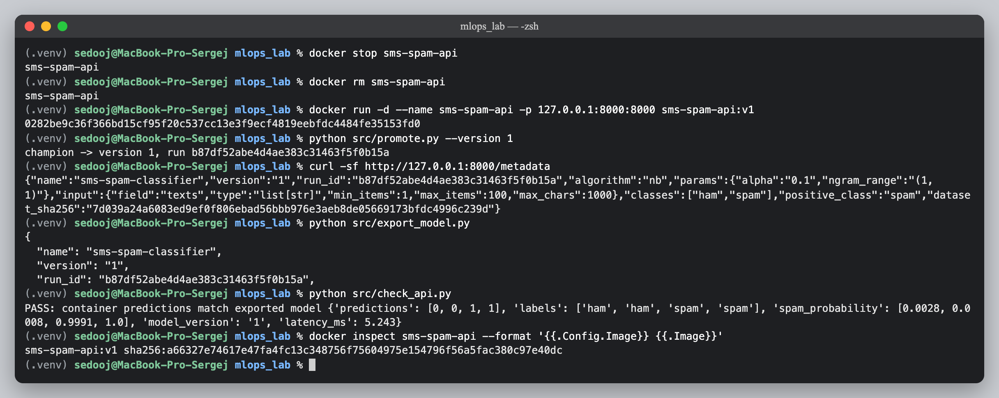

<center><b>Рисунок 22.</b> Откат: контейнер снова запущен из образа v1, champion возвращён на версию 1</center>

*Что подтверждает:* после отката /metadata показывает версию 1, образ контейнера `sms-spam-api:v1` с тем же ID `a66327e74617…`; после повторного экспорта эталон снова совпадает (PASS).

## 12. Запуск через Docker Compose и проверка healthcheck

Ручной контейнер останавливается, чтобы освободить порт. Чтобы не перезаписать сохранённый `v1`, используется отдельный тег
`compose-demo`. Он собирается из текущей `exported_model`, то есть из версии 1 после отката.

```bash
IMAGE_TAG=compose-demo docker compose up -d --build
docker compose ps
curl -sf http://127.0.0.1:8000/health
docker inspect mlops_lab-api-1 --format '{{json .State.Health}}'
docker compose logs --tail 15
docker compose down
```
Healthcheck выполняется **внутри контейнера**: `python -c "urllib.request.urlopen('http://127.0.0.1:8000/health')"`,
каждые 10 с, таймаут 3 с, 3 попытки, `start_period: 15s`. `restart: unless-stopped` перезапускает контейнер, если процесс
завершился. Сам по себе статус `unhealthy` перезапуска не вызывает. Volume не нужен, потому что модель включена в образ.

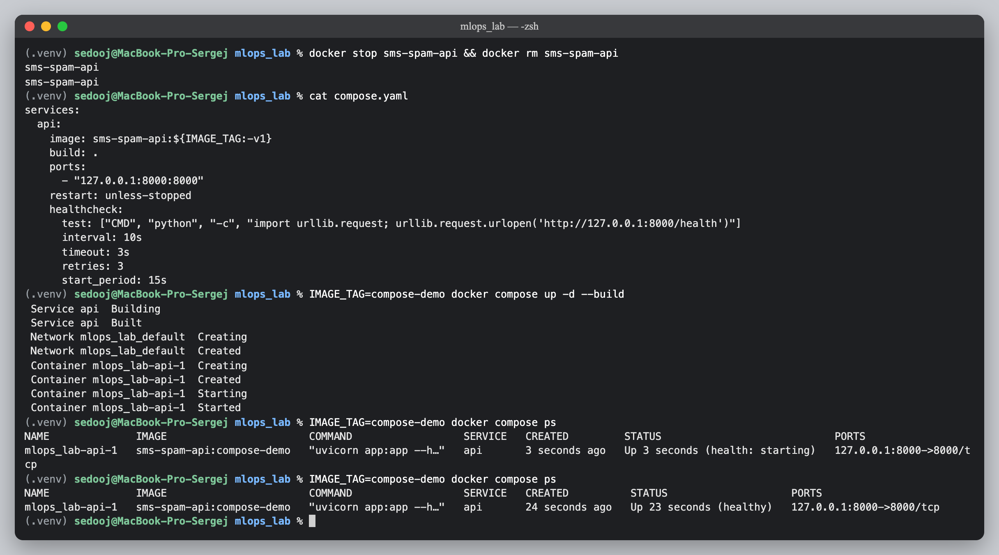

<center><b>Рисунок 23.</b> Запуск сервиса через Docker Compose: статус меняется с health: starting на healthy</center>

*Что подтверждает:* Compose собрал и запустил сервис, healthcheck прошёл успешно.

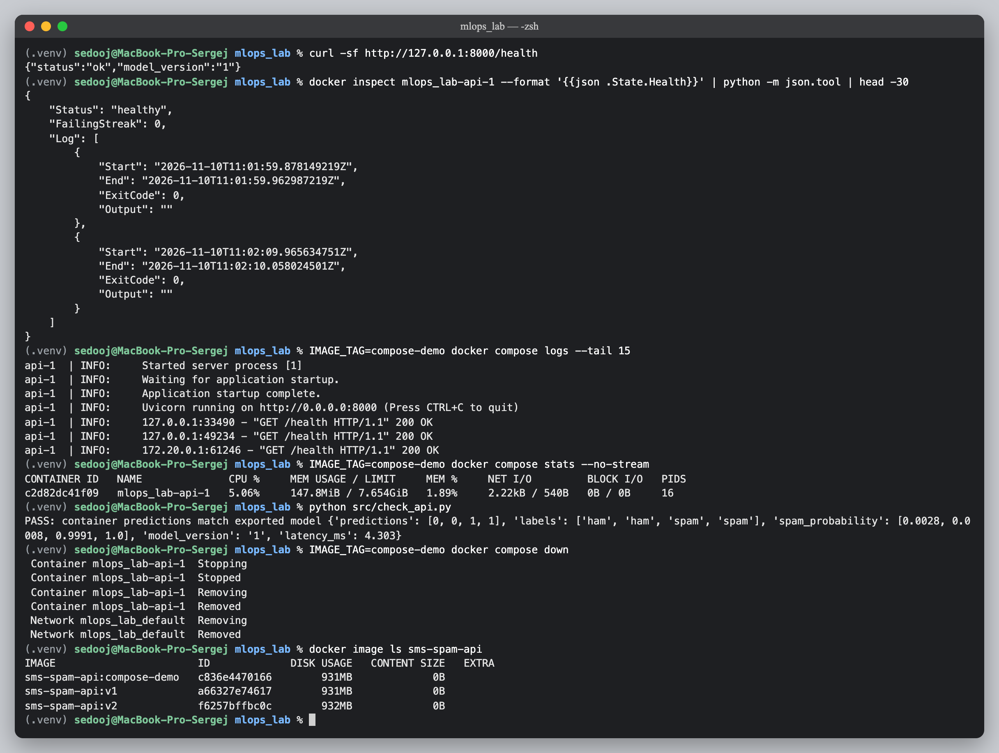

<center><b>Рисунок 24.</b> Health-лог контейнера, логи Compose, ресурсы, smoke-test и остановка</center>

*Что подтверждает:* проверки /health завершаются с ExitCode 0, API отвечает той же моделью версии 1; образы v1, v2 и compose-demo сохранены.

## 13. Фиксация зависимостей, данных и разбиения

| Что фиксируется | Как |
|---|---|
| Зависимости | `requirements.txt` (прямые, точные версии) и `requirements.lock.txt` (полный `pip freeze`); те же версии попадают в `pip_requirements` модели и в образ |
| Базовый образ | `python:3.12-slim`, digest `sha256:aa943ce4…d159` |
| Исходные данные | неизменяемый файл `data/raw/SMSSpamCollection`, его SHA-256 записан в тег каждого run и в `metadata.json` |
| Предобработка | код `src/data.py` логируется в артефакты каждого run |
| Разбиение | `random_state=42` + `stratify`, индексы train/val/test сохранены в `split.json` каждого run |
| Модель | номер версии Registry + `run_id` в `metadata.json` внутри образа; ID образа |
| Проверка воспроизводимости | регистрационные запуски 8 и 9 повторно обучены с теми же параметрами и дали **точно те же** метрики, что запуски 2 и 7 |

## 14. Выводы

1. Построен воспроизводимый цикл для задачи фильтрации SMS-спама (вариант 2): неизменённые исходные данные с SHA-256, дедупликация против утечки, стратифицированное разбиение 60/20/20, Pipeline «TF-IDF + классификатор», где векторизатор обучается только на train.
2. В MLflow выполнено 7 экспериментов. На качество сильнее всего влияют сглаживание `alpha` у NB (0,756 → 0,939 по F1_spam) и регуляризация `C` у LR (0,841 → 0,926). Биграммы при `alpha=0.1` на validation результат не изменили.
3. По заранее заданному правилу (макс. `val_f1_spam`, при равенстве — более простая модель) выбрана TF-IDF(1,1) + MultinomialNB(α=0,1). На test: F1_spam = 0.920, precision = 0.966, recall = 0.878, accuracy = 0.981. Эти значения близки к validation. Сравнение precision и recall показало компромисс: NB почти не даёт ложных срабатываний, а LR с `balanced` лучше находит спам.
4. В Model Registry две версии модели. Alias `champion` используется только при экспорте, а в образ попадает конкретная неизменяемая версия.
5. API на FastAPI с жёстким контрактом входа корректно отвечает 200 на валидные запросы и 422 на семь видов ошибочных. Ответы контейнера совпадают с экспортированной моделью.
6. Обновление v1 → v2 и откат v2 → v1 выполнены без переобучения и пересборки: откат — это просто запуск сохранённого образа. Различать тег образа, его ID, номер версии Registry и run_id оказалось необходимо: на эталонных SMS классы у версий совпадают, и смену модели видно только по метаданным и вероятностям.
7. Через Docker Compose сервис получил статус `healthy`.

**Сравнение кроме метрик:** воспроизводимость подтверждена совпадением метрик повторных запусков. Контракт API один и тот же для обеих версий модели. Размер образа ≈ 931 МБ, из них модель ≈ 0,34 МБ, остальное — окружение с полным MLflow. Для продакшена образ можно уменьшить, например через `mlflow-skinny` или чистый `skops/joblib`. Время обработчика ≈ 2–6 мс на пакет из 4 SMS, полный HTTP round-trip ≈ 8–12 мс.

## 15. Список использованных источников

1. Almeida T. A., Gómez Hidalgo J. M. SMS Spam Collection [Dataset]. UCI Machine Learning Repository, 2011. DOI: 10.24432/C5CC84. https://archive.ics.uci.edu/dataset/228/sms+spam+collection
2. MLflow Tracking Server. https://mlflow.org/docs/latest/self-hosting/architecture/tracking-server/
3. MLflow Model Registry. https://mlflow.org/docs/latest/ml/model-registry/tutorial/
4. MLflow sklearn API. https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html
5. MLflow network security. https://mlflow.org/docs/latest/self-hosting/security/network/
6. scikit-learn: Working With Text Data / TfidfVectorizer. https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
7. scikit-learn: Common pitfalls. https://scikit-learn.org/stable/common_pitfalls.html
8. scikit-learn: Model evaluation. https://scikit-learn.org/stable/modules/model_evaluation.html
9. FastAPI Request Body. https://fastapi.tiangolo.com/tutorial/body/
10. Pydantic: Strict mode and constrained types. https://docs.pydantic.dev/latest/concepts/strict_mode/
11. Dockerfile reference. https://docs.docker.com/reference/dockerfile/
12. Docker Compose: healthcheck. https://docs.docker.com/reference/compose-file/services/#healthcheck
13. Методические указания «Лабораторная работа 4. MLOps».

## Приложение А. Исходный код, зависимости, Dockerfile, Compose и примеры запросов

**`requirements.txt`**

```python
mlflow==3.5.0
scikit-learn==1.7.2
pandas==2.3.3
numpy==2.2.6
matplotlib==3.10.7
fastapi==0.119.0
uvicorn==0.37.0
sqlalchemy==2.0.44
```

**`src/data.py`**

```python
import csv
import hashlib
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path(__file__).resolve().parent.parent
RAW_PATH = ROOT / 'data' / 'raw' / 'SMSSpamCollection'
SOURCE_URL = 'https://archive.ics.uci.edu/dataset/228/sms+spam+collection'
SEED = 42
CLASSES = ['ham', 'spam']
TEXT_COL = 'text'


def file_sha256(path: Path = RAW_PATH) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def load_raw() -> pd.DataFrame:
    df = pd.read_csv(RAW_PATH, sep='\t', header=None, names=['label', TEXT_COL],
                     quoting=csv.QUOTE_NONE, encoding='utf-8')
    return df


def load_clean() -> pd.DataFrame:
    df = load_raw()
    df = df.drop_duplicates(subset=TEXT_COL, keep='first').reset_index(drop=True)
    df['target'] = (df['label'] == 'spam').astype(int)
    return df


def split(df: pd.DataFrame | None = None):
    if df is None:
        df = load_clean()
    X, y = df[[TEXT_COL]], df['target']
    Xdev, Xtest, ydev, ytest = train_test_split(X, y, test_size=.2, random_state=SEED, stratify=y)
    Xtrain, Xval, ytrain, yval = train_test_split(Xdev, ydev, test_size=.25, random_state=SEED,
                                                  stratify=ydev)
    return Xtrain, Xval, Xtest, ytrain, yval, ytest
```

**`src/train.py`**

```python
import argparse
import json
import os
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from data import CLASSES, RAW_PATH, SEED, SOURCE_URL, TEXT_COL, file_sha256, load_clean, split

MODEL_NAME = 'sms-spam-classifier'

p = argparse.ArgumentParser()
p.add_argument('--algorithm', choices=['nb', 'lr'], default='nb')
p.add_argument('--alpha', type=float, default=1.0, help='MultinomialNB smoothing')
p.add_argument('--c', type=float, default=1.0, help='LogisticRegression inverse regularization')
p.add_argument('--ngram-max', type=int, default=1, help='TF-IDF ngram_range=(1, ngram_max)')
p.add_argument('--class-weight', choices=['none', 'balanced'], default='none')
p.add_argument('--register', action='store_true')
a = p.parse_args()

mlflow.set_tracking_uri(os.getenv('MLFLOW_TRACKING_URI', 'http://127.0.0.1:5000'))
mlflow.set_experiment('lab4-sms-spam')

df = load_clean()
Xtrain, Xval, Xtest, ytrain, yval, ytest = split(df)

clf = (MultinomialNB(alpha=a.alpha) if a.algorithm == 'nb' else
       LogisticRegression(C=a.c, max_iter=2000, random_state=SEED,
                          class_weight=None if a.class_weight == 'none' else 'balanced'))
model = Pipeline([
    ('features', ColumnTransformer([('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, a.ngram_max),
                                                              sublinear_tf=True), TEXT_COL)])),
    ('clf', clf),
])

with mlflow.start_run(run_name=f'{a.algorithm}-experiment') as run:
    mlflow.log_params({'algorithm': a.algorithm, 'seed': SEED, 'dataset': 'UCI SMS Spam Collection',
                       'ngram_range': f'(1, {a.ngram_max})', 'n_train': len(Xtrain),
                       'n_validation': len(Xval), 'n_test': len(Xtest)})
    if a.algorithm == 'nb':
        mlflow.log_params({'alpha': a.alpha})
    else:
        mlflow.log_params({'C': a.c, 'class_weight': a.class_weight})
    mlflow.set_tags({'dataset_sha256': file_sha256(), 'purpose': 'lab4', 'variant': '2',
                     'selection_metric': 'val_f1_spam'})
    model.fit(Xtrain, ytrain)
    pred = model.predict(Xval)
    metrics = {'val_f1_spam': f1_score(yval, pred, pos_label=1),
               'val_precision_spam': precision_score(yval, pred, pos_label=1),
               'val_recall_spam': recall_score(yval, pred, pos_label=1),
               'val_accuracy': accuracy_score(yval, pred),
               'val_f1_macro': f1_score(yval, pred, average='macro')}
    mlflow.log_metrics(metrics)
    mlflow.log_input(mlflow.data.from_pandas(df[[TEXT_COL, 'target']], source=SOURCE_URL, targets='target',
                                             name='sms_spam_dedup'), context='full_dataset_before_split')
    mlflow.log_dict({'train_indices': Xtrain.index.tolist(), 'validation_indices': Xval.index.tolist(),
                     'test_indices': Xtest.index.tolist(), 'columns': [TEXT_COL],
                     'target_names': CLASSES, 'raw_file': RAW_PATH.name,
                     'preprocessing': 'drop_duplicates(text, keep=first); spam=1, ham=0'}, 'split.json')
    mlflow.log_artifact(__file__, artifact_path='source')
    mlflow.log_artifact(str(Path(__file__).with_name('data.py')), artifact_path='source')
    mlflow.log_artifact('requirements.txt', artifact_path='source')
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(yval, pred, display_labels=CLASSES, ax=ax)
    ax.set_title('Validation confusion matrix')
    mlflow.log_figure(fig, 'validation_confusion_matrix.png')
    plt.close(fig)
    info = mlflow.sklearn.log_model(model, name='model', input_example=Xtrain.head(2),
                                    signature=infer_signature(Xtrain, model.predict(Xtrain)),
                                    pip_requirements=Path('requirements.txt').read_text().splitlines())
    print(json.dumps({'run_id': run.info.run_id, 'model_uri': info.model_uri,
                      **{k: round(v, 4) for k, v in metrics.items()}}, indent=2))
    if a.register:
        mv = mlflow.register_model(info.model_uri, MODEL_NAME)
        print('REGISTERED_VERSION=', mv.version)
```

**`src/promote.py`**

```python
import argparse
import os

import mlflow
from mlflow import MlflowClient

MODEL_NAME = 'sms-spam-classifier'

p = argparse.ArgumentParser()
p.add_argument('--version', required=True)
p.add_argument('--alias', default='champion')
a = p.parse_args()
mlflow.set_tracking_uri(os.getenv('MLFLOW_TRACKING_URI', 'http://127.0.0.1:5000'))
c = MlflowClient()
v = c.get_model_version(MODEL_NAME, a.version)
c.set_registered_model_alias(MODEL_NAME, a.alias, a.version)
print(f'{a.alias} -> version {v.version}, run {v.run_id}')
```

**`src/export_model.py`**

```python
import json
import os
import shutil
from pathlib import Path

import mlflow
import mlflow.sklearn
import pandas as pd
from mlflow import MlflowClient

from data import CLASSES, TEXT_COL, file_sha256, split

MODEL_NAME = 'sms-spam-classifier'

mlflow.set_tracking_uri(os.getenv('MLFLOW_TRACKING_URI', 'http://127.0.0.1:5000'))
c = MlflowClient()
v = c.get_model_version_by_alias(MODEL_NAME, 'champion')
uri = f'models:/{MODEL_NAME}/{v.version}'
model = mlflow.sklearn.load_model(uri)
signature = mlflow.models.get_model_info(uri).signature
run = c.get_run(v.run_id)
Xtrain, Xval, Xtest, ytrain, yval, ytest = split()
out = Path('exported_model')
if out.exists():
    shutil.rmtree(out)
mlflow.sklearn.save_model(model, str(out), signature=signature, input_example=Xtrain.head(2),
                          pip_requirements=Path('requirements.txt').read_text().splitlines())

metadata = {'name': MODEL_NAME, 'version': v.version, 'run_id': v.run_id,
            'algorithm': run.data.params.get('algorithm'),
            'params': {k: run.data.params[k] for k in ('alpha', 'C', 'ngram_range', 'class_weight')
                       if k in run.data.params},
            'input': {'field': 'texts', 'type': 'list[str]', 'min_items': 1, 'max_items': 100,
                      'max_chars': 1000},
            'classes': CLASSES, 'positive_class': 'spam', 'dataset_sha256': file_sha256()}
(out / 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False))

sample = Xtest[ytest == 0].head(2)[TEXT_COL].tolist() + Xtest[ytest == 1].head(2)[TEXT_COL].tolist()
Path('sample_request.json').write_text(json.dumps({'texts': sample}, indent=2, ensure_ascii=False))
Path('expected_predictions.json').write_text(json.dumps(model.predict(pd.DataFrame({TEXT_COL: sample})).tolist()))
print(json.dumps(metadata, indent=2, ensure_ascii=False))
```

**`src/evaluate.py`**

```python
import json
from pathlib import Path

import mlflow.sklearn
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)

from data import CLASSES, split

m = mlflow.sklearn.load_model('exported_model')
meta = json.loads(Path('exported_model/metadata.json').read_text())
_, _, Xtest, _, _, ytest = split()
pred = m.predict(Xtest)
r = {'model_version': meta['version'], 'n_test': len(ytest),
     'test_f1_spam': f1_score(ytest, pred, pos_label=1),
     'test_precision_spam': precision_score(ytest, pred, pos_label=1),
     'test_recall_spam': recall_score(ytest, pred, pos_label=1),
     'test_accuracy': accuracy_score(ytest, pred),
     'test_f1_macro': f1_score(ytest, pred, average='macro'),
     'confusion_matrix': confusion_matrix(ytest, pred).tolist()}
Path('test_metrics.json').write_text(json.dumps(r, indent=2))
print(json.dumps(r, indent=2))
print(classification_report(ytest, pred, target_names=CLASSES, digits=4))
```

**`src/app.py`**

```python
import json
import logging
import time
from pathlib import Path
from typing import Annotated

import mlflow.sklearn
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, ConfigDict, Field, StringConstraints

MODEL_DIR = Path('/app/exported_model')
app = FastAPI(title='SMS spam classifier', version='1.0')
model = mlflow.sklearn.load_model(str(MODEL_DIR))
meta = json.loads((MODEL_DIR / 'metadata.json').read_text())
log = logging.getLogger('uvicorn.error')

SmsText = Annotated[str, StringConstraints(strip_whitespace=True, min_length=1, max_length=1000)]


class PredictRequest(BaseModel):
    model_config = ConfigDict(extra='forbid', strict=True)
    texts: list[SmsText] = Field(min_length=1, max_length=100)


@app.get('/health')
def health():
    return {'status': 'ok', 'model_version': meta['version']}


@app.get('/metadata')
def metadata():
    return meta


@app.post('/predict')
def predict(body: PredictRequest):
    start = time.perf_counter()
    X = pd.DataFrame({'text': body.texts})
    result = model.predict(X).astype(int).tolist()
    proba = model.predict_proba(X)[:, 1].round(4).tolist()
    elapsed = (time.perf_counter() - start) * 1000
    log.info('prediction model_version=%s rows=%s latency_ms=%.3f', meta['version'], len(X), elapsed)
    return {'predictions': result, 'labels': [meta['classes'][v] for v in result],
            'spam_probability': proba, 'model_version': meta['version'], 'latency_ms': round(elapsed, 3)}
```

**`src/check_api.py`**

```python
import json
import urllib.request
from pathlib import Path

body = Path('sample_request.json').read_bytes()
req = urllib.request.Request('http://127.0.0.1:8000/predict', data=body,
                             headers={'Content-Type': 'application/json'})
with urllib.request.urlopen(req, timeout=30) as r:
    result = json.load(r)
expected = json.loads(Path('expected_predictions.json').read_text())
assert result['predictions'] == expected, (result, expected)
print('PASS: container predictions match exported model', result)
```

**`Dockerfile`**

```dockerfile
FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY src/app.py /app/app.py
COPY exported_model /app/exported_model
RUN useradd --create-home appuser
USER appuser
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
```

**`.dockerignore`**

```text
.venv
.git
__pycache__
mlflow-data
mlartifacts
mlflow.db
screenshots
data
report
*.zip
*.ipynb
.DS_Store
mlruns
*.docx
```

**`compose.yaml`**

```yaml
services:
  api:
    image: sms-spam-api:${IMAGE_TAG:-v1}
    build: .
    ports:
      - "127.0.0.1:8000:8000"
    restart: unless-stopped
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health')"]
      interval: 10s
      timeout: 3s
      retries: 3
      start_period: 15s
```

**`exported_model/metadata.json`**

```json
{
  "name": "sms-spam-classifier",
  "version": "1",
  "run_id": "b87df52abe4d4ae383c31463f5f0b15a",
  "algorithm": "nb",
  "params": {
    "alpha": "0.1",
    "ngram_range": "(1, 1)"
  },
  "input": {
    "field": "texts",
    "type": "list[str]",
    "min_items": 1,
    "max_items": 100,
    "max_chars": 1000
  },
  "classes": [
    "ham",
    "spam"
  ],
  "positive_class": "spam",
  "dataset_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d"
}
```

**`sample_request.json`**

```json
{
  "texts": [
    "Aight, I should be there by 8 at the latest, probably closer to 7. Are jay and tyler down or should we just do two trips?",
    "Its ok my arm is feeling weak cuz i got a shot so we can go another time",
    "Todays Vodafone numbers ending with 4882 are selected to a receive a £350 award. If your number matches call 09064019014 to receive your £350 award.",
    "Urgent! Please call 09061743810 from landline. Your ABTA complimentary 4* Tenerife Holiday or #5000 cash await collection SAE T&Cs Box 326 CW25WX 150 ppm"
  ]
}
```

**`expected_predictions.json`**

```json
[0, 0, 1, 1]
```

**Примеры запросов**
```bash
curl -sf http://127.0.0.1:8000/health
curl -sf http://127.0.0.1:8000/metadata
curl -sf -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' --data-binary @sample_request.json
curl -s -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{"texts": ["WINNER!! You have won a FREE trip. Call 09061701461 now to claim, T&C apply"]}'
curl -s -X POST http://127.0.0.1:8000/predict -H 'Content-Type: application/json' -d '{"texts": []}'
```
Полный снимок окружения лежит в файле `requirements.lock.txt` (131 пакет). Полные логи команд сохранены в `report/logs/`.